# The Pedagogy direction will be

1. Setting up Gym environment: Custom environment
2. Baseline random policy
3. Training with PPO
4. Evaluation: (i) Training curve | (ii) Diagnostics | (iii) Learned path | (iv) Value function

#### This setup uses:

1. Gymnasium : ```pip install gymnasium```
2. Torch: ```pip install torch```
3. CleanRL

#### BONUS: OPTIONAL

```bash
python -m venv virtual_env_name
source insulin/bin/activate
pip install ipykernel
python -m ipykernel install --user --name=virtual_env_name --display-name="virtual_env_name"
```

In [1]:
import time
import numpy as np

import torch
import torch.nn as nn
import gymnasium as gym
from gymnasium import spaces
from gymnasium.wrappers import TimeLimit, RecordEpisodeStatistics
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle



In [2]:
torch.manual_seed(0) # sets up reproducible seed for all torch applications (neural network weights, probability distribution)
rng = np.random.default_rng(0) # An object is created random seed but locally unlike np.random.seed()

print("gymnasium", gym.__version__, "| torch", torch.__version__)

gymnasium 1.3.0 | torch 2.14.0


## [1] RL Setup

1. The environment hands the agent an **observation** of its current situation,
2. The agent picks an **action**,
3. The environment returns a **reward** (a single number saying how good that
   action was) and the **next observation**,
4. repeat, until the episode ends.

![RL Environment Loop](Images/environment-loop.png)

* Observation: What the agent currently sees
* Action: A choice the agent makes
* Reward: A number to say how good an action went
* Episode: One full attempt, start to some end condition
* Policy: The function mapping observation to action
* Return: The sum of rewards over an episode
---

### 1.1 Building the environment

A Gymnasium environment is a class implementing a setup

* ```observation_space```/```action_space```: Declare the shape of what the agent sees and can do.
* ```reset()->(observation, info)```: start a new episode
* ```step(action) -> (observation, reward, terminated, truncated, info)```: Advance one time-step. `terminated` means the episode ended *because of the dynamics* (goal reached, agent died); `truncated` means an external limit cut it off (a step budget). PPO's math needs to treat these two differently, which is why Gymnasium keeps them as separate flags.

**Problem Statement**

Environment :
* 5x5 grid
* Agent starts at top-left corner and must reach bottom right corner
* Obstacle : A wall down the middle blocking direct access, hence detour required

In [5]:
class GridWorldEnv(gym.Env):
    metadata = {'render_modes': ['ansi']}

    def __init__(self, size=5, walls= ((1,2), (2,2), (3,2)), start=(0,0), goal= (4,4)):
        super().__init__()
        self.size = size
        self.walls = set(walls)
        self.start = start
        self.goal = goal

        self.observation_space = spaces.Box(0.0, 1.0, shape=(size * size,), dtype=np.float32)
        self.action_space = spaces.Discrete(4)
        self._deltas = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}

    def _dist(self, pos):
        return abs(pos[0] - self.goal[0]) + abs(pos[1] - self.goal[1])

    def _obs(self):
        v = np.zeros(self.size * self.size, dtype=np.float32)
        r, c = self.agent_pos
        v[r * self.size + c] = 1.0 # Indexing which index should be 1
        return v

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.agent_pos = self.start
        return self._obs(), {}

    def step(self, action):
        dr, dc = self._deltas[int(action)]
        r, c = self.agent_pos
        nr, nc = r+dr, c+dc
        old_dist = self._dist(self.agent_pos)
        in_bounds = 0 <= nr < self.size and 0 <= nc < self.size
        if in_bounds and (nr, nc) not in self.walls:
            self.agent_pos =(nr, nc) # if didnt hit the wall or moved out the edge
        new_dist = self._dist(self.agent_pos)

        terminated = self.agent_pos == self.goal
        # -1.0 reduces the number of steps taken to reach the place
        # distance to the goal and if reached the goal then bigger bonus
        reward = -1.0 + 0.5 * (old_dist - new_dist) + (10.0 if terminated else 0.0)

        return self._obs(), reward, terminated, False, {}

    def render(self):
        rows=[]
        for r in range(self.size):
            row = []
            for c in range(self.size):
                if (r,c) == self.agent_pos:
                    row.append("A")
                elif (r, c) == self.goal:
                    row.append("G")
                elif (r, c) in self.walls:
                    row.append("#")
                else:
                    row.append(".")
            rows.append(" ".join(row))
        return "\n".join(rows)


**Trial run of the environment set up**

1. Actions will implemented = Right, Right, Left, Down
2. Observation and Reward will be seen


In [8]:
env = GridWorldEnv()
obs, info = env.reset()

print(f"reset(): obs.shape={obs.shape}, agent at {env.agent_pos}")
print(env.render())

for action, name in [(3, "right"), (3, "right"), (2, "left"), (1, "down")]:
    obs, reward, terminated, truncated, info = env.step(action)
    print(f"\nstep({name:<5}) -> reward={reward:+.2f} | terminated={terminated} | truncated={truncated} | agent at {env.agent_pos}")
    print(env.render())

reset(): obs.shape=(25,), agent at (0, 0)
A . . . .
. . # . .
. . # . .
. . # . .
. . . . G

step(right) -> reward=-0.50 | terminated=False | truncated=False | agent at (0, 1)
. A . . .
. . # . .
. . # . .
. . # . .
. . . . G

step(right) -> reward=-0.50 | terminated=False | truncated=False | agent at (0, 2)
. . A . .
. . # . .
. . # . .
. . # . .
. . . . G

step(left ) -> reward=-1.50 | terminated=False | truncated=False | agent at (0, 1)
. A . . .
. . # . .
. . # . .
. . # . .
. . . . G

step(down ) -> reward=-0.50 | terminated=False | truncated=False | agent at (1, 1)
. . . . .
. A # . .
. . # . .
. . # . .
. . . . G


In [9]:
# This is to check if the environment created adheres to Gymnasium API specification; space defination and signature checks
from gymnasium.utils.env_checker import check_env

check_env(GridWorldEnv(), skip_render_check=True)
print("check_env: no errors raised")

check_env: no errors raised


## [2] Baseline: random policy

* This part is to decide on a **baseline**. So we run this right now to see on average how a random policy behaves for 1000 episodes. Once we obtain the performance we use these values of mean return, success rate and mean length as something to compare to when we run the actual RL algorithm.

In [12]:
def make_base_env(max_episode_steps=50):
    """wrapping the raw environment in gymnasiums TimeLimit, makes sure that it returns truncated to true
    if more then max steps are reached"""
    return TimeLimit(GridWorldEnv(), max_episode_steps=max_episode_steps)

def run_episode(env, policy):
    # Runs one episode under 'policy(obs)->action'. Returns (path, total_return, length).
    obs, _ = env.reset()
    path = [env.unwrapped.agent_pos]
    total_return, length = 0.0, 0
    terminated = truncated = False
    while not (terminated or truncated):
        action = policy(obs)
        obs, reward, terminated, truncated, _ = env.step(action)
        path.append(env.unwrapped.agent_pos)
        total_return += reward
        length += 1
    return path, total_return, length

def random_policy(obs):
    return rng.integers(0, 4)

N_EPISODES = 1000
random_returns, random_lengths = [], []
for _ in range(N_EPISODES):
    _, ret, length = run_episode(make_base_env(), random_policy)
    random_returns.append(ret)
    random_lengths.append(length)

random_returns = np.array(random_returns)
random_lengths = np.array(random_lengths)
random_success = (random_lengths < 50).mean()

print(f"random policy over {N_EPISODES} episodes:")
print(f"  mean return   {random_returns.mean():7.2f}")
print(f"  success rate  {random_success:7.1%}   (reached the goal before the 50-step limit)")
print(f"  mean length   {random_lengths.mean():7.1f} steps")


random policy over 1000 episodes:
  mean return    -41.88
  success rate    21.7%   (reached the goal before the 50-step limit)
  mean length      46.2 steps


So blind exploration can yield a solution on randomly. Let us look at the movement of any one of the 1000 episodes could do.

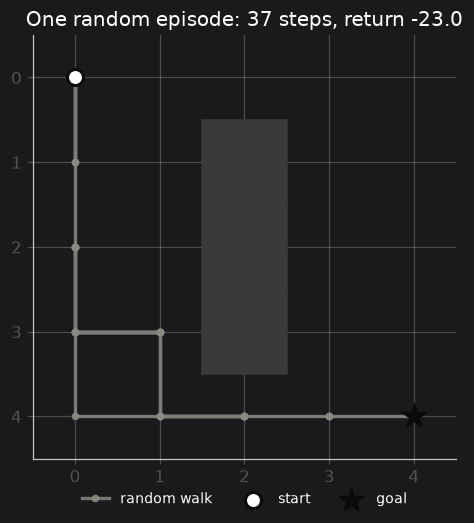

In [17]:
C_RANDOM = "#8a8983"   # the random-policy baseline
C_PPO    = "#1baf7a"   # the trained agent, the network we trained
C_TRUTH  = "#0b0b0b"   # start/goal markers, the analytic optimum
C_WALL   = "#3a3a38"

plt.rcParams.update({
    "figure.figsize": (7, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.edgecolor": "#c9c8c4", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 2.0, "font.size": 11, "legend.frameon": False,
})

def draw_grid(ax, env, path=None, path_color=C_PPO, path_label=None, values=None):
    size = env.size
    im = None
    if values is not None:
        im = ax.imshow(values, cmap="Blues", vmin=np.nanmin(values), vmax=np.nanmax(values))
    for (r, c) in env.walls:
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, color=C_WALL, zorder=2))
    if path is not None:
        rs = [p[0] for p in path]
        cs = [p[1] for p in path]
        ax.plot(cs, rs, color=path_color, lw=2.2, marker="o", ms=4,
                 label=path_label, zorder=4, alpha=0.85)
    ax.scatter([env.start[1]], [env.start[0]], marker="o", s=110, facecolors="white",
               edgecolors=C_TRUTH, linewidths=2, zorder=5, label="start")
    ax.scatter([env.goal[1]], [env.goal[0]], marker="*", s=280, color=C_TRUTH, zorder=5, label="goal")
    ax.set_xlim(-0.5, size - 0.5)
    ax.set_ylim(size - 0.5, -0.5)
    ax.set_xticks(range(size)); ax.set_yticks(range(size))
    ax.set_aspect("equal")
    ax.grid(True, color="#e3e2de", linewidth=0.8)
    return im


example_path, example_return, example_length = run_episode(make_base_env(), random_policy)

fig, ax = plt.subplots(figsize=(5, 5))
draw_grid(ax, GridWorldEnv(), path=example_path, path_color=C_RANDOM, path_label="random walk")
ax.set_title(f"One random episode: {example_length} steps, return {example_return:.1f}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, fontsize=9)
plt.show()

## [3] Training an RL problem with PPO

**PPO** (Proximal Policy Optimization)